In [ ]:
import json, pickle
from pathlib import Path
import numpy as np

RESULTS = Path('results')
def load(name):
    with open(RESULTS / f'{name}.pkl', 'rb') as fh:
        return pickle.load(fh)

metadata = json.load(open(RESULTS / 'metadata.json'))
cfg = metadata['config']
print('device:', metadata['device'], '| seeds/cell:', metadata['seeds_per_cell'])
print('main-sweep width:', cfg['n_hidden'], '| max steps:', cfg['max_steps'],
      '| optimizer:', cfg['optimizer'], '| lr:', cfg['learning_rate'])
print('noise levels:', cfg['noise_levels'])
main = load('main_sweep'); hidden = load('hidden_sweep')

# --- live-training setup for the controllable curve panels ---
import torch, blob_experiments
from blob_task import BlobTask
from blob_experiments import BlobConfig
# DEVICE = torch.device('cuda:1' if (torch.cuda.is_available() and
#                        torch.cuda.device_count() > 1) else
#                       ('cuda:0' if torch.cuda.is_available() else 'cpu'))

DEVICE = 'cpu'
task = BlobTask(DEVICE)
def make_config(**overrides):
    base = dict(metadata['config']); base.update(overrides)
    return BlobConfig(**base)
print('live-train device:', DEVICE)

device: cuda:1 | seeds/cell: 256
main-sweep width: 16 | max steps: 4000 | optimizer: sgd | lr: 0.05
noise levels: [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
live-train device: cpu


In [10]:
# --- plotting setup ---
dodge = position_dodge(width=0.6)
stimColors = {'Rule': '#715cad', 'Exception': '#6fa8dc'}

In [ ]:
# FIG_NOISE  = 1.75
FIG_NOISE  = 0.85
FIG_HIDDEN = 64
FIG_INIT   = 0.005      # weight_init_std (rich)
# FIG_STEPS  = 20000
FIG_STEPS  = 30000
FIG_SEEDS  = 50        # more = tighter SEM bands (slower)
FIG_SNAPS  = [300, FIG_STEPS // 2, FIG_STEPS]   # PCA snapshot steps
# accuracy_mode = 'argmax'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)
accuracy_mode = 'expected'   # 'argmax' (hard) or 'expected' (soft, sigmoid confidence)

fig2_data = blob_experiments.compute_curve_data(
    make_config(), task, noise_levels=[FIG_NOISE], n_hidden=FIG_HIDDEN,
    weight_init_std=FIG_INIT, num_steps=FIG_STEPS, num_seeds=FIG_SEEDS,
    accuracy_mode=accuracy_mode, record_rep_steps=FIG_SNAPS)
print('fig2_data ready; snapshots', fig2_data['snapshots'])

fig2_data ready; snapshots [300, 15000, 30000]


## Experiment 1 Figures

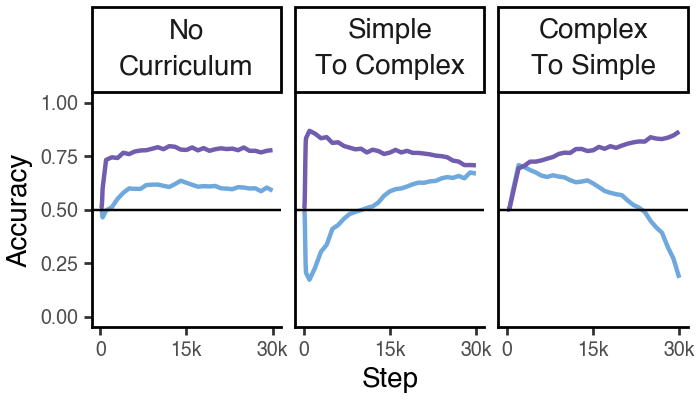

In [12]:
# ===== Networks: learning dynamics per curriculum (plotnine, human-figure style) =====
import numpy as np, pandas as pd
from plotnine import *

# display order; label paired with its NN condition so the two can't drift apart
PANELS = [('No\nCurriculum',     'standard'),
          ('Simple\nTo Complex', 'curriculum'),
          ('Complex\nTo Simple', 'anti_curriculum')]
CURR_ORDER = [lab for lab, _ in PANELS]

d  = fig2_data
ck = np.asarray(d['checkpoints'])

nn = pd.concat([
    pd.DataFrame({'curriculum': c, 'stimType': stim, 'step': ck,
                  'mean_acc': d[f'{cc}_{key}'][0], 'se': d[f'{cc}_{key}_sem'][0]})
    for c, cc in PANELS
    for stim, key in (('Rule', 'central'), ('Exception', 'peripheral'))],
    ignore_index=True)
nn['ymin'] = nn['mean_acc'] - nn['se']
nn['ymax'] = nn['mean_acc'] + nn['se']
nn['curriculum'] = pd.Categorical(nn['curriculum'], CURR_ORDER, ordered=True)
max_step = int(ck.max())

p = (
    ggplot(nn, aes(x='step', y='mean_acc', color='stimType', group='stimType'))
    + geom_ribbon(aes(ymin='ymin', ymax='ymax', fill='stimType'),
                  alpha=0.25, color='none')
    + geom_line(size=0.9)
    + facet_wrap('~curriculum')
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + scale_x_continuous(limits=(0, max_step), breaks=[0, max_step / 2, max_step],
                         labels=lambda ls: ['0' if v == 0 else f'{v/1000:g}k' for v in ls])
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + scale_fill_manual(values=stimColors)
    + theme_classic()
    + labs(x='Step', y='Accuracy', color='Stimulus Type')
    + theme(axis_text=element_text(size=7), text=element_text(size=10),
            figure_size=(3.5, 2), panel_spacing_x=0.02, legend_position='none')
)
p

# p.save(
#     filename='../analysis/figs/fig2A.svg',
#     format="svg",
#     verbose=False
# )

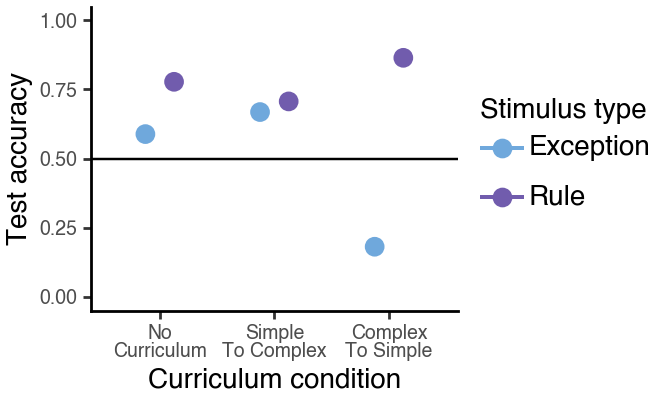

In [13]:
# ===== Networks: final ("test") accuracy by curriculum and stimType =====
import numpy as np, pandas as pd
from plotnine import *

PANELS = [('No\nCurriculum',     'standard'),
          ('Simple\nTo Complex', 'curriculum'),
          ('Complex\nTo Simple', 'anti_curriculum')]
CURR_ORDER = [lab for lab, _ in PANELS]

d = fig2_data          # the network's "test" = last checkpoint on the clean prototypes
summary_test = pd.DataFrame([
    {'curriculum': c, 'stimType': stim,
     'mean_acc': d[f'{cc}_{key}'][0][-1], 'se': d[f'{cc}_{key}_sem'][0][-1]}
    for c, cc in PANELS
    for stim, key in (('Rule', 'central'), ('Exception', 'peripheral'))])
summary_test['ymin'] = summary_test['mean_acc'] - summary_test['se']
summary_test['ymax'] = summary_test['mean_acc'] + summary_test['se']
summary_test['curriculum'] = pd.Categorical(summary_test['curriculum'],
                                            CURR_ORDER, ordered=True)

dodge = position_dodge(width=0.5)
p_test = (
    ggplot(summary_test, aes(x='curriculum', y='mean_acc', color='stimType'))
    + geom_point(position=dodge, size=3)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=0.2, position=dodge)
    + labs(x='Curriculum condition', y='Test accuracy', color='Stimulus type')
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + theme(axis_text_x=element_text(rotation=0, ha='center', size=11))
    + theme(axis_text=element_text(size=7), text=element_text(size=10),
            figure_size=(3.3, 2))
)

p_test

# p_test.save(
#     filename="../analysis/figs/fig2B.svg",
#     format="svg",
#     verbose=False
# )

## Why does curriculum benefit?

## Experiment 2 Figures

In [81]:
# === Experiment 2: pretraining (1-D rule vs XOR) -> type-5 transfer ===
import blob_pretrain as bp2

# PRE_NOISE     = 0.85     # transfer + pretrain input-noise std (matches FIG_NOISE)
# TRAN_NOISE    = 0.85     # transfer input-noise std (matches FIG_NOISE)
# PRE_HIDDEN    = 64       # width  (rich regime, as in Figure 2)
# PRE_INIT      = 0.005    # weight_init_std (rich / feature-learning)
# PRE_PRE       = 20000     # pretraining steps
# PRE_TRANSFER  = 2000    # type-5 transfer steps
# PRE_SEEDS     = 10       # nets per (kind x schedule); more = tighter bands
# PRE_KINDS     = ('none', '1d', 'xor')
# RESET_READOUT = False   # True = carry over only pretrained features (fresh readout)
# ACCURACY_MODE = 'expected'   # <- TOGGLE: 'expected' (soft/sigmoid) or 'argmax' (hard 0/1)

PRE_NOISE     = 0.0     # transfer + pretrain input-noise std (matches FIG_NOISE)
TRAN_NOISE    = 0.85     # transfer input-noise std (matches FIG_NOISE)
PRE_HIDDEN    = 64       # width  (rich regime, as in Figure 2)
PRE_INIT      = 0.005    # weight_init_std (rich / feature-learning)
PRE_PRE       = 20000     # pretraining steps
PRE_TRANSFER  = 8000    # type-5 transfer steps
PRE_SEEDS     = 50       # nets per (kind x schedule); more = tighter bands
PRE_KINDS     = ('none', '1d', 'xor')
RESET_READOUT = True   # True = carry over only pretrained features (fresh readout)
ACCURACY_MODE = 'expected'   # <- TOGGLE: 'expected' (soft/sigmoid) or 'argmax' (hard 0/1)
LR = 0.01

pt = bp2.train_pretrain_transfer(
    make_config(weight_init_std=PRE_INIT, n_hidden=PRE_HIDDEN, accuracy_mode=ACCURACY_MODE),
    task, transfer_noise=TRAN_NOISE, pretrain_noise=PRE_NOISE,
    pretrain_steps=PRE_PRE, transfer_steps=PRE_TRANSFER, num_seeds=PRE_SEEDS,
    pretrain_kinds=PRE_KINDS, reset_readout=RESET_READOUT)
print('pretrain->transfer ready; kinds', pt['pretrain_kinds'],
      '| reset_readout', pt['reset_readout'])


pretrain->transfer ready; kinds ['none', '1d', 'xor'] | reset_readout True


In [ ]:
# ===== Pretraining accuracy + participation ratio (dual y-axis) =====
# Plotnine has no sec_axis in 0.15, so PR is rescaled onto the primary [0.5, 1]
# axis for plotting, then a matplotlib twinx is attached to label it as PR.
import numpy as np, pandas as pd
from plotnine import *

PRETRAIN_ORDER = [k for k in PRE_KINDS if k in pt['pretrain_curve']]
PR_COLOR = '#CC5500'   # dark orange for PR lines, right spine, right tick labels

def _load(metric, sem_key):
    return pd.concat([
        pd.DataFrame({
            'pretraining': k,
            'bin_mid':  pt['pretrain_curve'][k]['checkpoints'],
            'y':        pt['pretrain_curve'][k][metric],
            'sem':      pt['pretrain_curve'][k][sem_key],
        }) for k in PRETRAIN_ORDER
    ], ignore_index=True)

acc = _load('accuracy', 'accuracy_sem')
pr  = _load('participation_ratio', 'participation_ratio_sem')
for df in (acc, pr):
    df['pretraining'] = pd.Categorical(df['pretraining'], PRETRAIN_ORDER, ordered=True)

# ---- broken/compressed x-axis: [0, SPLIT] true scale; tail compressed ----
max_trial   = int(acc['bin_mid'].max())
SPLIT       = 1500
TAIL_WIDTH  = 800
TAIL_START  = int(max_trial * 0.9)

def remap(x):
    x = np.asarray(x, dtype=float)
    y = x.copy()
    tail = x > SPLIT
    y[tail] = SPLIT + (x[tail] - TAIL_START) / (max_trial - TAIL_START) * TAIL_WIDTH
    return y

def _trim(df):
    d = df[(df['bin_mid'] <= SPLIT) | (df['bin_mid'] >= TAIL_START)].copy()
    d['x_display'] = remap(d['bin_mid'])
    return d
acc, pr = _trim(acc), _trim(pr)

# ---- rescale PR into primary [0.5, 1] axis coords ----
PR_MIN = float(np.floor(pr['y'].min()))
PR_MAX = float(np.ceil(pr['y'].max()))
pr['y_scaled']   = 0.5 + (pr['y'] - PR_MIN) / (PR_MAX - PR_MIN) * 0.5
pr['ymin']       = pr['y_scaled'] - (pr['sem'] / (PR_MAX - PR_MIN) * 0.5)
pr['ymax']       = pr['y_scaled'] + (pr['sem'] / (PR_MAX - PR_MIN) * 0.5)
acc['ymin']      = acc['y'] - acc['sem']
acc['ymax']      = acc['y'] + acc['sem']

# ---- pick markers at evenly spaced display-x targets (raw checkpoints are
# dense early / sparse late, so stride-based thinning looks irregular) ----
visual_max = SPLIT + TAIL_WIDTH
N_MARKERS  = 8
def _thin_even(df):
    out = []
    for _, g in df.groupby('pretraining', observed=True):
        g = g.sort_values('x_display').reset_index(drop=True)
        targets = np.linspace(g['x_display'].min(), g['x_display'].max(), N_MARKERS)
        idx = sorted({int(np.abs(g['x_display'].values - t).argmin()) for t in targets})
        out.append(g.iloc[idx])
    return pd.concat(out, ignore_index=True)
acc_pts = _thin_even(acc)
pr_pts  = _thin_even(pr)

p = (
    ggplot(acc, aes(x='x_display', y='y', shape='pretraining'))
    # PR overlay drawn FIRST so it sits behind the accuracy lines
    + geom_line(data=pr,
                mapping=aes(x='x_display', y='y_scaled', shape='pretraining'),
                color=PR_COLOR, alpha=0.8, size=0.9, linetype='dashed',
                inherit_aes=False)
    + geom_point(data=pr_pts,
                 mapping=aes(x='x_display', y='y_scaled', shape='pretraining'),
                 color=PR_COLOR, alpha=0.8, size=1.5, inherit_aes=False)
    + geom_errorbar(data=pr_pts,
                    mapping=aes(x='x_display', ymin='ymin', ymax='ymax',
                                shape='pretraining'),
                    color=PR_COLOR, alpha=0.8, width=TAIL_WIDTH * 0.03,
                    inherit_aes=False)
    # Accuracy on top
    + geom_line(size=1)
    + geom_point(data=acc_pts, size=2)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'),
                    data=acc_pts, width=TAIL_WIDTH * 0.03)
    + labs(x='Trial', y='Accuracy', color='')
    + scale_x_continuous(limits=(0, visual_max),
                         breaks=[0, SPLIT, visual_max],
                         labels=['0', f'{SPLIT/1000:g}k', f'{max_trial/1000:g}k'])
    + scale_y_continuous(limits=(0.45, 1.05), expand=(0, 0))
    + theme_classic()
    + theme(axis_text=element_text(size=7), text=element_text(size=10),
            figure_size=(1.6, 2), legend_position='none')
)

# ---- draw & mirror plotnine's own axis styling onto the twin ----
fig = p.draw()
ax  = fig.axes[0]

# introspect the primary (plotnine-drawn) axis so the twin/slashes match exactly
left_spine = ax.spines['left']
SPINE_LW   = left_spine.get_linewidth()

tick_line  = ax.yaxis.get_major_ticks()[0].tick1line
TICK_W     = tick_line.get_markeredgewidth()
TICK_LEN   = tick_line.get_markersize()
TICK_DIR   = 'out' if tick_line.get_marker() == 0 else 'out'   # plotnine uses 'out'

tick_fp    = ax.get_yticklabels()[0].get_fontproperties().copy()
label_fp   = ax.yaxis.label.get_fontproperties().copy()

# force primary (accuracy) axis fully black (spine/ticks/label)
ax.tick_params(axis='y', colors='black', labelcolor='black',
               width=TICK_W, length=TICK_LEN, direction=TICK_DIR)
ax.yaxis.label.set_color('black')
left_spine.set_color('black')

# right-hand PR axis: match plotnine's font, spine and tick geometry;
# orange tick labels + spine (match PR lines), black axis title
ax_r = ax.twinx()
ax_r.patch.set_visible(False)
ax_r.set_ylim(PR_MIN - 1, PR_MAX + 1)
ax_r.spines['top'].set_visible(False)
ax_r.spines['left'].set_visible(False)
ax_r.spines['bottom'].set_visible(False)
ax_r.spines['right'].set_color(PR_COLOR)
ax_r.spines['right'].set_linewidth(SPINE_LW)
ax_r.tick_params(axis='y', width=TICK_W, length=TICK_LEN, direction=TICK_DIR,
                 colors=PR_COLOR, labelcolor=PR_COLOR)
ax_r.set_ylabel('Participation ratio', color='black')
ax_r.yaxis.label.set_fontproperties(label_fp)
ax_r.yaxis.label.set_color('black')
for lbl in ax_r.get_yticklabels():
    lbl.set_fontproperties(tick_fp)
    lbl.set_color(PR_COLOR)

# ---- axis-break slashes drawn on the x-axis (matplotlib idiom, axes coords) ----
# use the same linewidth as the plotnine spine so they read as part of the axis.
x0, x1 = ax.get_xlim()
frac = (SPLIT + TAIL_WIDTH * 0.10 - x0) / (x1 - x0)
gap  = (TAIL_WIDTH * 0.14) / (x1 - x0)
d    = 0.015          # slash half-length in axes coords
kw = dict(transform=ax.transAxes, color='black', clip_on=False, lw=SPINE_LW,
          solid_capstyle='butt')
ax.plot((frac - d,       frac + d),       (-d, +d), **kw)
ax.plot((frac + gap - d, frac + gap + d), (-d, +d), **kw)

fig

fig.savefig('../analysis/figs/fig4B.svg',
            format='svg', bbox_inches='tight')


/opt/anaconda3/envs/nlp/lib/python3.12/site-packages/plotnine/scales/scale_shape.py:82: PlotnineWarning: Using shapes for an ordinal variable is not advised.


In [ ]:
# ===== Transfer learning dynamics: curriculum x pretraining x stimType =====
import numpy as np, pandas as pd
from plotnine import *

CURR_PANELS = [('No\nCurriculum',     'standard'),
               ('Simple\nTo Complex', 'curriculum')]
CURR_ORDER = [lab for lab, _ in CURR_PANELS]
PRETRAIN_ORDER = [k for k in PRE_KINDS if k != 'none']   # match human: 1d + xor onlyz
STIM_GROUPS = (('Rule', 'central'), ('Exception', 'peripheral'))

ck_tr = np.asarray(pt['checkpoints'])

summary_learn = pd.concat([
    pd.DataFrame({
        'curriculum_label': curr_lab,
        'pretraining':      kind,
        'stimType':         stim,
        'bin_mid':          ck_tr,
        'mean_acc':         pt[kind][f'{cc}_{key}'],
        'sem':              pt[kind][f'{cc}_{key}_sem'],
    })
    for curr_lab, cc in CURR_PANELS
    for kind in PRETRAIN_ORDER
    for stim, key in STIM_GROUPS
], ignore_index=True)
summary_learn['ymin'] = summary_learn['mean_acc'] - summary_learn['sem']
summary_learn['ymax'] = summary_learn['mean_acc'] + summary_learn['sem']
summary_learn['curriculum_label'] = pd.Categorical(
    summary_learn['curriculum_label'], CURR_ORDER, ordered=True)
summary_learn['pretraining'] = pd.Categorical(
    summary_learn['pretraining'], PRETRAIN_ORDER, ordered=True)

# Sub-sample only the marker/errorbar layer to declutter (keep line dense)
POINT_STRIDE = 4                       # every Nth checkpoint gets a point + errorbar
point_ck = set(ck_tr[::POINT_STRIDE].tolist()) | {int(ck_tr[-1])}
points_learn = summary_learn[summary_learn['bin_mid'].isin(point_ck)]

max_trial = int(ck_tr.max())
p_learn = (
    ggplot(summary_learn, aes(x='bin_mid', y='mean_acc',
                              color='stimType', shape='pretraining'))
    + geom_line()
    + geom_point(data=points_learn)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), data=points_learn, width=6)
    + facet_wrap('~curriculum_label')
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + labs(x='Trial', y='Accuracy', shape='Pretraining', color='Stimulus Type')
    + scale_x_continuous(limits=(0, max_trial))
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + theme(axis_text=element_text(size=7), axis_text_x=element_text(size=6), text=element_text(size=10),
            figure_size=(2.5, 2), panel_spacing_x=0.04, legend_position='none')
)

p_learn

p_learn.save(
    filename='../analysis/figs/fig4C.svg',
    format='svg',
    verbose=False,
)


/opt/anaconda3/envs/nlp/lib/python3.12/site-packages/plotnine/scales/scale_shape.py:82: PlotnineWarning: Using shapes for an ordinal variable is not advised.


In [72]:
# ===== Transfer test accuracy: curriculum x pretraining x stimType =====
import numpy as np, pandas as pd
from plotnine import *

CURR_PANELS = [('No\nCurriculum',     'standard'),
               ('Simple\nTo Complex', 'curriculum')]
CURR_ORDER = [lab for lab, _ in CURR_PANELS]
PRETRAIN_ORDER = [k for k in PRE_KINDS if k != 'none']   # 1d + xor only
STIM_GROUPS = (('Rule', 'central'), ('Exception', 'peripheral'))

summary_test_pre = pd.DataFrame([
    {'curriculum_label': curr_lab, 'pretraining': kind, 'stimType': stim,
     'mean_acc': pt[kind][f'{cc}_{key}'][-1],
     'sem':      pt[kind][f'{cc}_{key}_sem'][-1]}
    for curr_lab, cc in CURR_PANELS
    for kind in PRETRAIN_ORDER
    for stim, key in STIM_GROUPS
])
summary_test_pre['ymin'] = summary_test_pre['mean_acc'] - summary_test_pre['sem']
summary_test_pre['ymax'] = summary_test_pre['mean_acc'] + summary_test_pre['sem']
summary_test_pre['curriculum_label'] = pd.Categorical(
    summary_test_pre['curriculum_label'], CURR_ORDER, ordered=True)
summary_test_pre['pretraining'] = pd.Categorical(
    summary_test_pre['pretraining'], PRETRAIN_ORDER, ordered=True)

dodge_pt = position_dodge(width=0.6)
p_test_pre = (
    ggplot(summary_test_pre, aes(x='curriculum_label', y='mean_acc',
                                 color='stimType', shape='pretraining'))
    + geom_point(position=dodge_pt, size=2)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=0.2, position=dodge_pt)
    + labs(x='Curriculum', y='Accuracy',
           color='Stimulus type', shape='Pretraining')
    + scale_y_continuous(limits=(0.5, 1))
    + scale_x_discrete(labels={'1d': 'Simple\n Pretraining', 'xor': 'XOR\n Pretraining'})
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + geom_hline(yintercept=0.5, linetype='dashed', color='black', alpha=1)
    + theme(axis_text=element_text(size=7), text=element_text(size=10),
            figure_size=(2.6, 2), legend_text=element_text(size=7),
            legend_key_height=8)
)

p_test_pre

p_test_pre.save(
    filename='../analysis/figs/fig4D.svg',
    format='svg',
    verbose=False,
)


/opt/anaconda3/envs/nlp/lib/python3.12/site-packages/plotnine/scales/scale_shape.py:82: PlotnineWarning: Using shapes for an ordinal variable is not advised.
